<h1 style="color: #4166c4; font-weight: 700;">Exploratory Data Analysis <a id="toc"></a></h1>

<h2>Table of Contents</h2>

- [1. Introduction](#intro)
- [2. Data Preparation](#P0)
  - [2.1 Load the datasets](#P01)
- [3. Data Understanding](#P1)
  - [3.1 General Exploration](#P11)
    - [3.1.1 Shape and data types](#P111)
    - [3.1.2 Missing values](#P112)
    - [3.1.3 Duplicate records and lyrics](#P113)
  - [3.2 Univariate Analysis](#P12)
    - [3.2.1 Categorical features](#P121)
    - [3.2.2 Numerical features](#P122)
      - [Most-viewed songs](#P1221)
      - [Year distribution and consistency](#P1222)
    - [3.2.3 Text characteristics](#P123)
  - [3.3 Multivariate Analysis](#P13)
    - [3.3.1 Views, genres, and artists](#P131)
- [4. Preprocessing Plan](#P14)

<h2 style="color: #4166c4; font-weight: 400;">1. Introduction <a id="intro"></a></h2>

This exploratory data analysis examines the structure, quality, and content of the song-lyrics dataset. It summarizes missing and duplicate records, genre balance, artist and year metadata, and lyric vocabulary, sentiment-related signals, formatting, and structure. The findings will guide data-cleaning decisions and provide context for the project?s lyrics-only genre-classification task and its sentiment analysis.

The results are descriptive rather than causal; suspicious values and repeated lyrics should be reviewed before changing the data. Analyses based on samples or filtered years are noted where relevant.

<h2 style="color: #4166c4; font-weight: 400;">2. Data Preparation <a id="P0"></a></h2>

<h3 style="color: #597edb; font-weight: 400;">2.1 Load the datasets <a id="P01"></a></h3>

In [1]:
#pip install matplotlib
#pip install seaborn 

<h4>Import the required libraries</h4>

In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'data').is_dir() and (path / 'tools').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate the project root containing data/ and tools/.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(sys.executable)

c:\Users\almad\Documents\3rd year\1st semester\TextMining\projeto\Text-Mining-\.venv\Scripts\python.exe


In [3]:
%pip install nltk Unidecode python-dotenv better-profanity

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import importlib
import tools.utils as utils


PRIMARY_COLOR = "#4166c4"
SECONDARY_COLOR = "#597edb"
CHART_COLORS = sns.color_palette(sns.light_palette(SECONDARY_COLOR, n_colors=6, reverse=True))
plt.rcParams.update({'axes.titlecolor': SECONDARY_COLOR, 'axes.titleweight': 'normal'})

<h4>Load the training and test datasets</h4>

In [5]:
df_train = pd.read_csv(PROJECT_ROOT / 'data' / 'train.csv')
df_test = pd.read_csv(PROJECT_ROOT / 'data' / 'test.csv')

print(f'Train shape: {df_train.shape}')
print(f'Test shape: {df_test.shape}')

Train shape: (134967, 8)
Test shape: (33742, 7)


The training data is divided into training and validation sets before modeling. This provides a held-out portion for model evaluation.

<h2 style="color: #4166c4; font-weight: 400;">3. Data Understanding <a id="P1"></a></h2>

<h3 style="color: #597edb; font-weight: 400;">3.1 General Exploration <a id="P11"></a></h3>

[Back to table of contents](#toc)

<h4>3.1.1 Shape and data types <a id="P111"></a></h4>

Inspect the dataset dimensions, column types, and basic numeric ranges.

In [6]:
df_train.info()
df_train.describe()

<class 'pandas.DataFrame'>
RangeIndex: 134967 entries, 0 to 134966
Data columns (total 8 columns):
 #   Column    Non-Null Count   Dtype
---  ------    --------------   -----
 0   title     134965 non-null  str  
 1   tag       134967 non-null  str  
 2   artist    134967 non-null  str  
 3   year      134967 non-null  int64
 4   views     134967 non-null  int64
 5   features  134967 non-null  str  
 6   lyrics    134967 non-null  str  
 7   id        134967 non-null  int64
dtypes: int64(3), str(5)
memory usage: 8.2 MB


,year,views,id
count,134967.000000,1.349670e+05,1.349670e+05
mean,2009.467537,3.413344e+03,3.593871e+06
std,46.287743,4.192449e+04,2.323217e+06
min,1.000000,0.000000e+00,2.800000e+01
25%,2008.000000,2.200000e+01,1.414202e+06
50%,2015.000000,8.900000e+01,3.547995e+06
75%,2019.000000,4.730000e+02,5.600458e+06
max,2024.000000,3.604497e+06,7.882826e+06


We will fix the inconsistency of having `year` stored as a string by converting it to a proper date type and having the minimum year as 1.

<h4>3.1.2 Missing values <a id="P112"></a></h4>

In [7]:
print(df_train.isnull().sum())

title       2
tag         0
artist      0
year        0
views       0
features    0
lyrics      0
id          0
dtype: int64


Check for missing or empty lyric text.

In [8]:
# Checking empty and missing review texts
print("missing text lyrics:", df_train['lyrics'].isnull().sum())
print("empty text lyrics:", (df_train['lyrics'].str.strip() == '').sum())

missing text lyrics: 0
empty text lyrics: 0


<h4>3.1.3 Duplicate records and lyrics <a id="P113"></a></h4>

<h5>Exact duplicate records within and between datasets</h5>

In [9]:
# Count exact duplicate rows within each dataset.
train_full_row_duplicates = int(df_train.duplicated().sum())
test_full_row_duplicates = int(df_test.duplicated().sum())

# Compare distinct rows over columns shared by train and test (for example, train has a target column).
shared_columns = [column for column in df_train.columns if column in df_test.columns]
train_shared_rows = df_train[shared_columns].drop_duplicates()
test_shared_rows = df_test[shared_columns].drop_duplicates()
train_test_exact_rows = train_shared_rows.merge(
    test_shared_rows,
    on=shared_columns,
    how='inner',
).drop_duplicates()

print(f'Exact duplicate rows within train: {train_full_row_duplicates}')
print(f'Exact duplicate rows within test: {test_full_row_duplicates}')
print(f'Distinct exact rows shared between train and test: {len(train_test_exact_rows)}')

Exact duplicate rows within train: 0
Exact duplicate rows within test: 0
Distinct exact rows shared between train and test: 0


<h5>Repeated lyrics within and between datasets</h5>

In [10]:
# Compare non-empty, exact lyric strings in train and test.
def non_empty_lyrics(frame):
    mask = frame['lyrics'].map(lambda value: isinstance(value, str) and bool(value.strip()))
    return frame.loc[mask]

train_lyrics_rows = non_empty_lyrics(df_train)
test_lyrics_rows = non_empty_lyrics(df_test)

for split_name, frame in [('Train', train_lyrics_rows), ('Test', test_lyrics_rows)]:
    group_columns = {'row_count': ('id', 'size')}
    if 'tag' in frame.columns:
        group_columns['genre_count'] = ('tag', 'nunique')
    counts = frame.groupby('lyrics').agg(**group_columns)
    repeated = counts[counts['row_count'] > 1]
    print(f'{split_name} duplicate lyric groups: {len(repeated)}')
    print(f'{split_name} duplicate rows beyond first: {int((repeated["row_count"] - 1).sum())}')
    if 'genre_count' in repeated.columns:
        conflicts = repeated[repeated['genre_count'] > 1]
        print(f'{split_name} duplicate groups with conflicting genres: {len(conflicts)}')
        print(f'{split_name} rows in conflicting groups: {int(conflicts["row_count"].sum())}')
    empty_count = int((frame['lyrics'].map(lambda value: isinstance(value, str) and not value.strip())).sum())
    missing_count = int(frame['lyrics'].isna().sum())
    print(f'{split_name} empty lyric rows: {empty_count}')
    print(f'{split_name} missing lyric rows: {missing_count}')

train_lyric_set = set(train_lyrics_rows['lyrics'])
test_lyric_set = set(test_lyrics_rows['lyrics'])
shared_lyrics = train_lyric_set & test_lyric_set
train_overlap_rows = train_lyrics_rows[train_lyrics_rows['lyrics'].isin(shared_lyrics)]
test_overlap_rows = test_lyrics_rows[test_lyrics_rows['lyrics'].isin(shared_lyrics)]
print(f'Exact lyric strings shared between train and test: {len(shared_lyrics)}')
print(f'Train rows with lyrics also present in test: {len(train_overlap_rows)}')
print(f'Test rows with lyrics also present in train: {len(test_overlap_rows)}')

Train duplicate lyric groups: 165
Train duplicate rows beyond first: 178
Train duplicate groups with conflicting genres: 13
Train rows in conflicting groups: 26
Train empty lyric rows: 0
Train missing lyric rows: 0
Test duplicate lyric groups: 11
Test duplicate rows beyond first: 13
Test empty lyric rows: 0
Test missing lyric rows: 0
Exact lyric strings shared between train and test: 72
Train rows with lyrics also present in test: 90
Test rows with lyrics also present in train: 77


Repeated lyrics are not automatically duplicate records: different songs or versions may share lyrics, and repeated training lyrics may have conflicting genre labels. The cross-dataset check identifies exact lyric strings shared by train and test, which should be considered when assessing leakage. These checks use the raw lyric strings; Unicode/whitespace normalization may merge, split, or otherwise change the duplicate counts, so rerun them after normalization before deciding what to remove.

In [11]:
# Inspect repeated lyrics within each dataset and lyrics shared across train and test.
for split_name, frame in [('Train', train_lyrics_rows), ('Test', test_lyrics_rows)]:
    duplicated_rows = frame[frame.duplicated(subset=['lyrics'], keep=False)].sort_values('lyrics')
    print(f'{split_name} rows with repeated lyrics: {len(duplicated_rows)}')
    with pd.option_context('display.max_rows', None, 'display.max_colwidth', 100):
        display(duplicated_rows.head( ))

print('Train rows whose lyrics also occur in test:')
with pd.option_context('display.max_rows', None, 'display.max_colwidth', 100):
    display(train_overlap_rows.head( ))
print('Test rows whose lyrics also occur in train:')
with pd.option_context('display.max_rows', None, 'display.max_colwidth', 100):
    display(test_overlap_rows.head( ))

Train rows with repeated lyrics: 343


,title,tag,artist,year,views,features,lyrics,id
14594,Damage Ive Done Moby Sad Gospel mix,pop,The Heads,2015,14,{},"""There's buzzin' and ringin' in my ear\nAnd I wonder where do I go from here\nThe moments missed...",1442530
111409,Damage Ive Done Sound/Bisquit vocal mix,pop,The Heads,2015,12,{},"""There's buzzin' and ringin' in my ear\nAnd I wonder where do I go from here\nThe moments missed...",1214596
16236,Phillis Wheatley’s “On Being Brought from Africa to America”,misc,ChrisApap,2014,112,{},"'Twas mercy brought me from my Pagan land,\nTaught my benighted soul to understand\nThat there's...",518757
71910,Phillis Wheatley’s “On Being Brought from Africa to America”,misc,Dr. Katy Evans,2014,20,{},"'Twas mercy brought me from my Pagan land,\nTaught my benighted soul to understand\nThat there's...",365464
22751,Fingertips Part 1 Second Pressing,rb,Stevie Wonder,1963,56,{},"'Yeah'\n'Yeah'\n\nLadies and gentlemen, now I'm going to do a song\nTaken from my album, 'The Ja...",3767965


Test rows with repeated lyrics: 24


,title,artist,year,views,features,lyrics,id
57,Piotr Czerski’s “We the Web Kids” Liza Paley,#CA346,2014,21,"{""Tony Tran""}",1. We grew up with the Internet and on the Internet. This is what makes us different; this is wh...,559911
29409,Piotr Czerski’s “We the Web Kids” 21,Jerdotcom,2014,0,{},1. We grew up with the Internet and on the Internet. This is what makes us different; this is wh...,585026
5592,Equal College Access,Christian Castillo,2017,9,{},Assignment (4 Steps: 10 Annotations):\n1. Highlight this entire article (including instructions)...,3017311
18372,Equal Access To College,Nahsiem Mccombs,2017,10,{},Assignment (4 Steps: 10 Annotations):\n1. Highlight this entire article (including instructions)...,3016034
636,Penetration Assemblage 23 remix,Haujobb,2015,8,{},For a little piece of a second\nI have seen men\nBlinking and sparkling\nTest-screen coloured\nW...,1821933


Train rows whose lyrics also occur in test:


,title,tag,artist,year,views,features,lyrics,id
2621,Equal college access,misc,Marion Pratt,2017,32,{},Assignment (4 Steps: 10 Annotations):\n1. Highlight this entire article (including instructions)...,3017305
3016,Pokemon Rap : Bullet Punchlines,rap,Shofu,2013,4036,"{""VI Seconds""}",Shizzy Sixx:\n\nSuicune Sixx bringing flames again\nUnintimidated cuz I got these trainers read\...,131909
3107,No One Else Will Sing To Me,pop,Anymore,2015,15,{},Don't be frightened\nWhen you're with me\nThey can't hurt you\nYou're in safety\nWhen you're wit...,1377280
5639,I Dont Remember Live Single Version,pop,Peter Gabriel,1983,45,{},[Verse 1]\nI got no means to show identification\nI got no papers show you what I am\nYou'll hav...,4870792
6529,I Me Mine,rock,The Beatles,1970,55246,{},"[Verse 1]\nAll through the day\nI me mine, I me mine, I me mine\nAll through the night\nI me min...",123446


Test rows whose lyrics also occur in train:


,title,artist,year,views,features,lyrics,id
103,Doctorin The House,Coldcut,2015,206,{},Doctorin' the house\nDoctorin'\nDoctorin'\nWe've got a hot one for you\nCan you take care of it?...,1764060
357,Pardon My Ways,Busta Rhymes,2015,115,{},Tell us that you would like to have the lyrics of this song. Then we'll make it our highest prio...,1849654
1526,Ya Win Some Ya Lose Some,Wiley,2012,229,{},Tell us that you would like to have the lyrics of this song. Then we'll make it our highest prio...,969779
1761,Lane Navachi,Lunascape,2002,672,{},She does not like me\nSomebody shot her in a rainbow\nOn Lane Navachi\nShe never ran to save her...,1293221
2120,Anon’s “We Are Anonymous” Roy Rosas,#CA346S15,2015,3,"{""Jeremy Morris""}","GREETINGS, PEOPLE OF THE WORLD - WE ARE ANONYMOUS\n\nThere are many theories about us. That we’r...",725679


Full-row duplicates and repeated lyrics are different checks: the first compares all columns within a dataset, while the second groups by the lyric text regardless of metadata. The train/test overlap check compares lyric strings across the two datasets. All lyric comparisons here are exact comparisons before normalization; normalization can change which rows match. Reassess counts on normalized lyrics, then apply an explicit duplicate policy that preserves labels and the required test-set rows/order.

<h3 style="color: #597edb; font-weight: 400;">3.2 Univariate Analysis <a id="P12"></a></h3>

<h4>3.2.1 Categorical features <a id="P121"></a></h4>

<h5>Genre distribution and class balance</h5>

In [12]:
print(df_train['tag'].value_counts()) #checking what genres we have and how many songs per genre


tag
pop        55742
rap        38584
rock       25332
rb          6203
misc        5640
country     3466
Name: count, dtype: int64


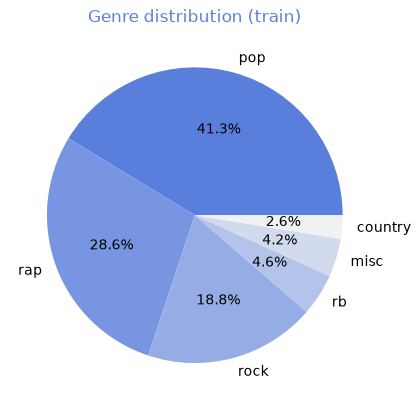

In [13]:
# Checking genre balance in the training dataset

palette = sns.color_palette(CHART_COLORS[:df_train['tag'].nunique()])
df_train['tag'].value_counts().plot.pie(autopct ='%1.1f%%', ylabel = '', colors=palette)
plt.title('Genre distribution (train)', color=SECONDARY_COLOR, fontweight='normal')
plt.show()

The dataset contains six genres: `country`, `misc`, `pop`, `rap`, `rb`, and `rock`. The class distribution is not perfectly balanced, with some genres appearing much more frequently than others. This means the training data is dominated by a few classes, which can bias the model toward predicting the majority genres more often. In practice, this suggests that we should be careful with evaluation metrics and consider class-weighting or resampling strategies later in the modeling pipeline. The imbalance is also important because it may affect how we interpret performance across genres, especially for the minority classes.

<h5>Lyrics by genre</h5>

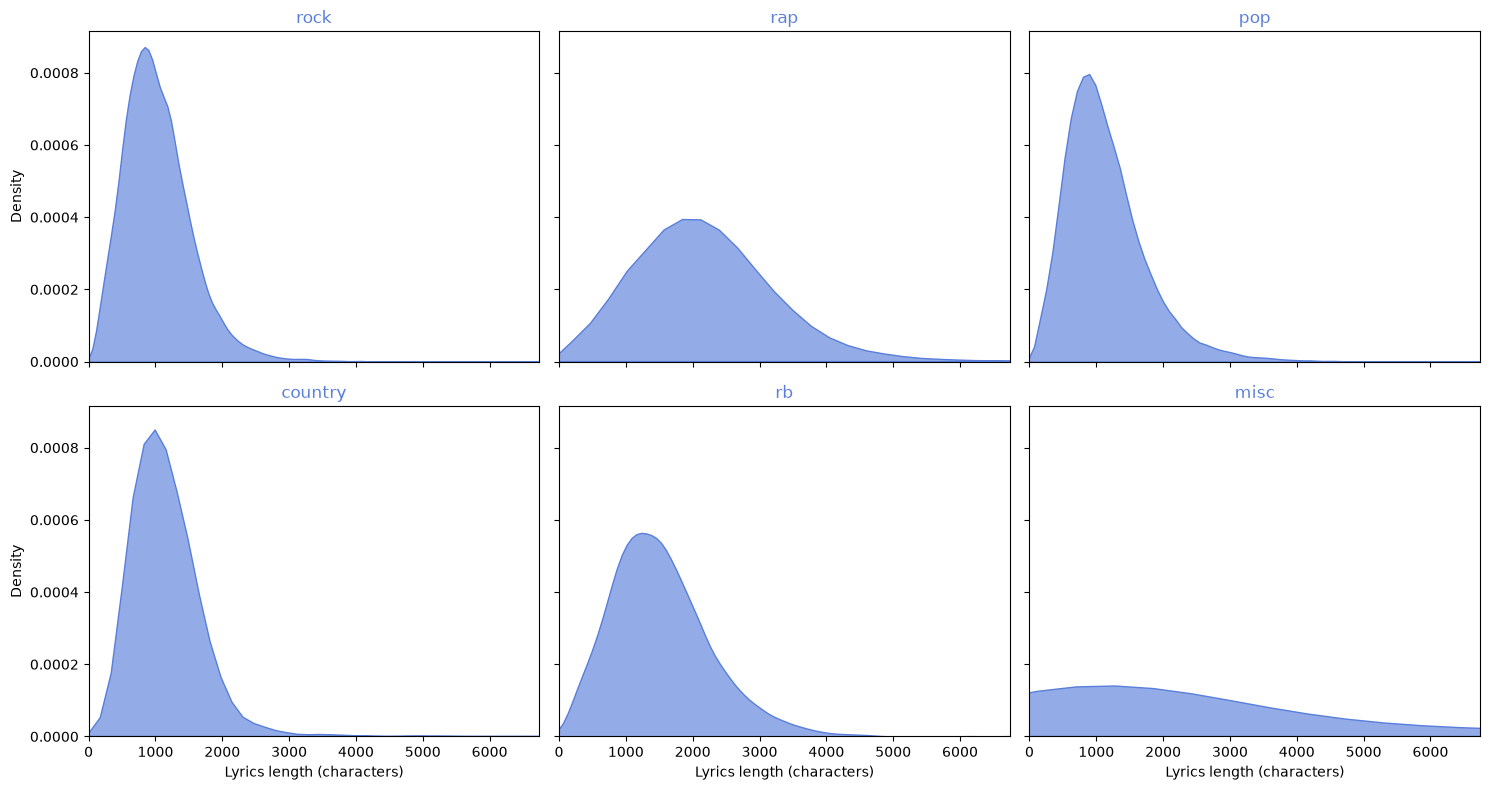

In [14]:
# distributions of lyrics size per music genre

tags = df_train['tag'].unique()
df_train['lyrics_length'] = df_train['lyrics'].str.len()

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
pink = SECONDARY_COLOR

for ax, tag in zip(axes.flatten(), tags):
    subset = df_train[df_train['tag'] == tag]
    sns.kdeplot(data=subset, x='lyrics_length', ax=ax, fill=True, color=pink, alpha=0.65)
    ax.set_title(tag, color=SECONDARY_COLOR, fontweight='normal')
    ax.set_xlabel('Lyrics length (characters)')

plt.xlim(0, df_train['lyrics_length'].quantile(0.99))  # clip long tail
plt.tight_layout()
plt.savefig(PROJECT_ROOT / 'lyrics_length_by_tag.png', dpi=150)
plt.show()

<h5>Artist frequency</h5>

In [15]:
artists = df_train['artist'].unique().tolist()#getting the list of unique artist so we can later deal with the non musicians
print(f"Total unique artists: {len(artists)}")

Total unique artists: 74916


In [16]:

# Top 10 most frequent artists in the training set
top_artists = df_train['artist'].value_counts().head(10)
display(top_artists)

artist
Genius English Translations    555
The Grateful Dead               86
Emily Dickinson                 75
Abraham Lincoln                 59
OCTOBERSFULLMOON                58
Lil B                           52
Holy Bible (KJV)                50
Gucci Mane                      49
KIDZ BOP Kids                   49
Charles Dickens                 48
Name: count, dtype: int64

We analyzed the `artist` variable by counting how many songs each artist appears with in the training data.

This is useful to check whether the dataset is dominated by a few artists, whether some artists are overrepresented, and whether there may be artist-level leakage across train/test splits or across genres. It also helps us spot repeated artists that could distort model training if not handled carefully.

We also identified that the most frequent artist is actually a translator rather than an artist in the musical sense, so those songs need to be assigned to their corresponding actual artist before we can draw meaningful conclusions about artist-level patterns. This is important because otherwise the artist counts would be misleading and could distort the analysis of artist imbalance and potential leakage.

In short, this analysis gives us a quick view of artist imbalance and provides a first signal for downstream checks such as duplicate artists, cross-genre artist distribution, and possible data leakage.

<h5>Song feature counts</h5>

In [17]:
# 'features' looks like {A,B,"C D"}: count items, treating quoted names as one item
feature_count = df_train['features'].str.findall(r'"(?:[^"\\]|\\.)*"|[^,{}"]+').str.len()

zero_features = (feature_count == 0).sum()
one_feature = (feature_count == 1).sum()
more_than_one_feature = (feature_count > 1).sum()

print(f"Songs with 0 features: {zero_features}")
print(f"Songs with exactly 1 feature: {one_feature}")
print(f"Songs with more than 1 feature: {more_than_one_feature}")


Songs with 0 features: 111928
Songs with exactly 1 feature: 18265
Songs with more than 1 feature: 4774


<h4>3.2.2 Numerical features <a id="P122"></a></h4>

<h5>Most-viewed songs <a id="P1221"></a></h5>

In [18]:
top_10_songs = (
    df_train.nlargest(10, 'views')[['title', 'views']]
    .reset_index(drop=True)
)

display(top_10_songs)

,title,views
0,Hit Em Up,3604497
1,V. 3005,3325127
2,Plain Jane Remix,3235312
3,Dusk Till Dawn,3033507
4,Nice For What,2942444
5,Energy,2781485
6,Broccoli,2660782
7,​hot girl bummer,2613320
8,Love on the Brain,2223025
9,Hope,2185037


<h5>Year distribution and consistency <a id="P1222"></a></h5>

In [19]:
raw_year = pd.read_csv(PROJECT_ROOT / 'data' / 'train.csv', usecols=['year'])['year']

# Handle years stored either as numbers or date strings
year_num = pd.to_numeric(raw_year, errors='coerce')
date_year = pd.to_datetime(raw_year, errors='coerce').dt.year
year_num = year_num.fillna(date_year).dropna().astype(int)

songs_per_year = year_num.value_counts().sort_index()

display(songs_per_year.rename('song_count').to_frame())
print(f"Unique years: {year_num.nunique()}")

,song_count
year,
1,45
3,1
4,1
6,1
7,1
...,...
2020,14027
2021,12368
2022,2707


Unique years: 282


The year column contains implausible values (including very small integers) and is currently inconsistent in representation. Treat these as candidates for validation and correction, not as reliable release years.

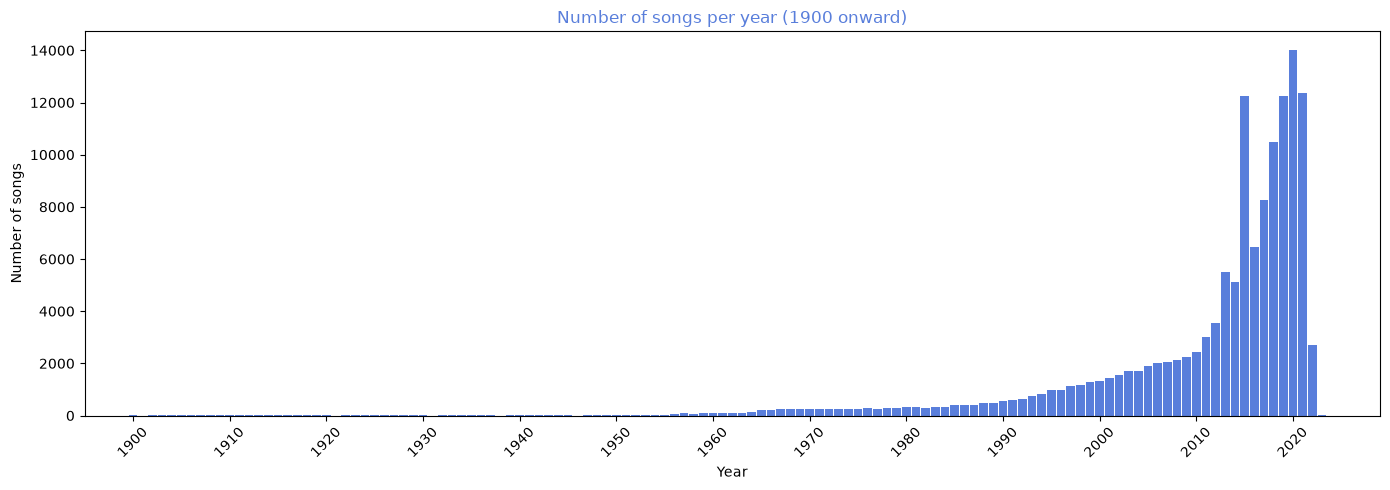

In [20]:
# Clean the year field and keep only realistic values
year_series = pd.read_csv(PROJECT_ROOT / 'data' / 'train.csv', usecols=['year'])['year'].astype(str).str.strip()

year_num = pd.to_numeric(year_series, errors='coerce')
date_year = pd.to_datetime(year_series, errors='coerce').dt.year

clean_year = year_num.fillna(date_year)
clean_year = clean_year[(clean_year >= 1900) & (clean_year <= 2030)].astype(int)

years_to_plot = clean_year
year_counts = years_to_plot.value_counts().sort_index()

plt.figure(figsize=(14, 5))
plt.bar(year_counts.index, year_counts.values, color=SECONDARY_COLOR, width=0.9)
decade_ticks = range(1900, ((year_counts.index.max() // 10) + 1) * 10, 10)
plt.xticks(decade_ticks, rotation=45)
plt.xlim(1895, year_counts.index.max() + 5)
plt.title('Number of songs per year (1900 onward)', color=SECONDARY_COLOR, fontweight='normal')
plt.xlabel('Year')
plt.ylabel('Number of songs')
plt.tight_layout()
plt.show()

This plot filters to years from 1900 onward only to make the distribution easier to inspect. The filter is a visualization choice, not a cleaning rule; validate suspicious years separately before changing the data.

<h4>3.2.3 Text characteristics <a id="P123"></a></h4>

This section explores lyric vocabulary, repetition, profanity, annotations, and structure. These characteristics may be useful for both project objectives: the genre-classification model uses lyrics as its only input, while sentiment analysis also relies on the language and expression in the lyrics. In particular, vocabulary and repetition can reveal patterns worth investigating for sentiment, and explicit-language measures provide one limited signal. These summaries are exploratory; profanity or structure alone should not be treated as a sentiment label or assumed to improve a model.

<h5>Vocabulary by genre</h5>

,avg_unique_words
tag,
misc,312.8
rap,180.9
rb,105.2
country,95.8
pop,89.7
rock,87.7


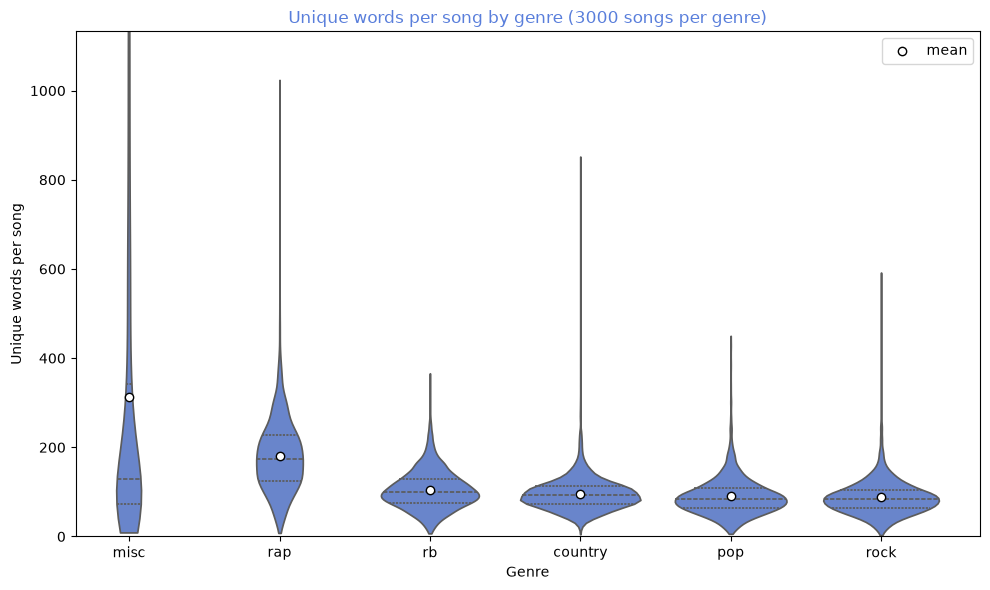

In [21]:
#vocabulary per genery 

# 3000 random songs per genre so every genre is compared on equal footing
sample_df = df_train.groupby('tag').sample(n=3000, random_state=42).copy()

# lowercase, drop [Chorus]-style annotations, keep only words
words = sample_df['lyrics'].str.lower().str.replace(r'\[.*?\]', ' ', regex=True).str.findall(r"\b\w+\b")
sample_df['word_count'] = words.str.len()
sample_df['unique_word_count'] = words.apply(lambda w: len(set(w)))

mean_unique = sample_df.groupby('tag')['unique_word_count'].mean().sort_values(ascending=False)
display(mean_unique.round(1).rename('avg_unique_words').to_frame())

fig, ax = plt.subplots(figsize=(10, 6))
sns.violinplot(data=sample_df, x='tag', y='unique_word_count', order=mean_unique.index,
               color=pink, inner='quartile', cut=0, ax=ax)
ax.scatter(range(len(mean_unique)), mean_unique.values, color='white', edgecolor='black', zorder=3, label='mean')
ax.set_ylim(0, sample_df['unique_word_count'].quantile(0.99))  # clip long tail
ax.set_title('Unique words per song by genre (3000 songs per genre)', color=SECONDARY_COLOR, fontweight='normal')
ax.set_xlabel('Genre')
ax.set_ylabel('Unique words per song')
ax.legend()
plt.tight_layout()
plt.show()

The table and violin plot compare the average number of **distinct words per song** across 3,000 sampled songs per genre. In this sample, **misc** has the largest average vocabulary (312.8 unique words per song), while **rock** has the smallest (87.7). This is a raw count, so longer lyrics can contain more unique words; it measures vocabulary size per song, not vocabulary density. Vocabulary is relevant to genre classification because lyrics are the model's only input, and variation in word choice may also be informative for sentiment analysis.

<h5>Type-token ratio (TTR)</h5>

,avg_ttr
tag,
misc,0.512
rock,0.462
rap,0.434
pop,0.425
country,0.424
rb,0.367


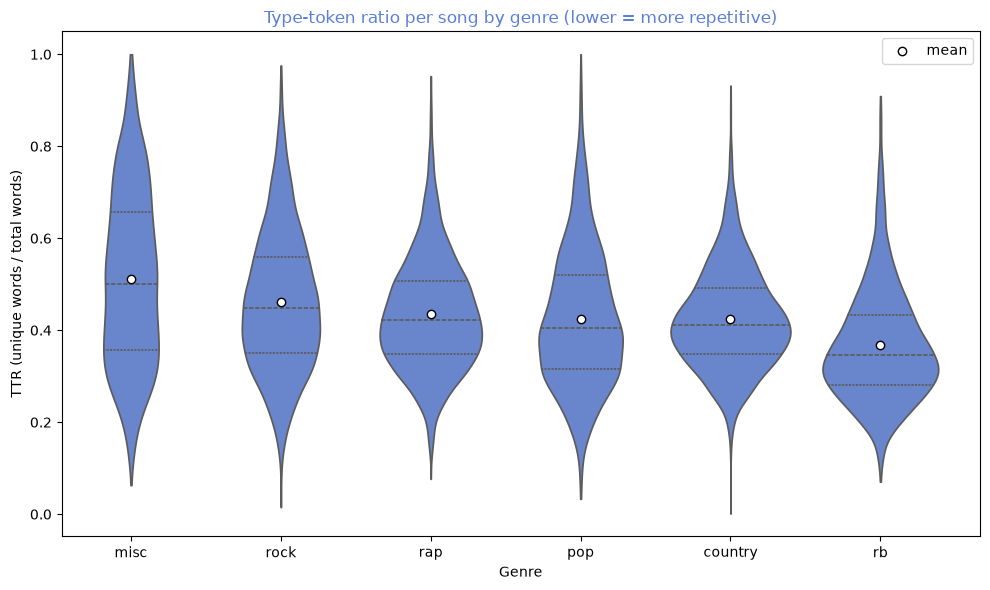

In [22]:
#Repetitive score TTR
sample_df['ttr'] = sample_df['unique_word_count'] / sample_df['word_count'].replace(0, np.nan)

mean_ttr = sample_df.groupby('tag')['ttr'].mean().sort_values(ascending=False)
display(mean_ttr.round(3).rename('avg_ttr').to_frame())

fig, ax = plt.subplots(figsize=(10, 6))
sns.violinplot(data=sample_df, x='tag', y='ttr', order=mean_ttr.index,
               color=pink, inner='quartile', cut=0, ax=ax)
ax.scatter(range(len(mean_ttr)), mean_ttr.values, color='white', edgecolor='black', zorder=3, label='mean')
ax.set_title('Type-token ratio per song by genre (lower = more repetitive)', color=SECONDARY_COLOR, fontweight='normal')
ax.set_xlabel('Genre')
ax.set_ylabel('TTR (unique words / total words)')
ax.legend()
plt.tight_layout()
plt.show()

The type-token ratio (TTR) is the number of unique words (types) divided by the total number of words (tokens) in a song. It ranges from 0 to 1; higher values indicate a larger share of unique words in the lyric. Differences in lexical diversity and repetition may be worth exploring for sentiment analysis, but TTR alone does not indicate whether a lyric is positive or negative.

460 profane word forms found in the sample


,pct_explicit,avg_profane_per_100_words
tag,,
rap,88.47,2.75
misc,49.93,0.59
rb,44.83,0.75
rock,35.30,0.57
country,30.97,0.35
pop,29.47,0.42


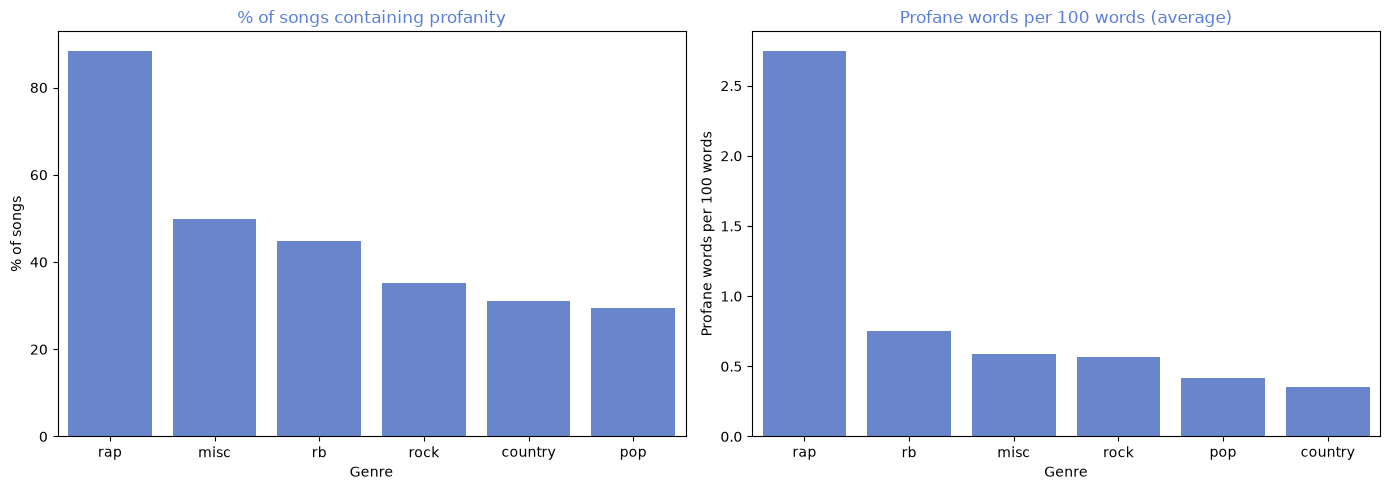

In [23]:


# Profanity score
from better_profanity import profanity

profanity.load_censor_words()
profanity.add_censor_words(['hoe', 'hoes', 'thot', 'thots', 'nigguh', 'bitchy', 'mf', 'mfs', 'fuckboy', 'fuckboys', 'shiit'])

# check each distinct word once instead of every word of every song ('words' comes from the vocabulary cell)
vocab = set(w for song in words for w in song)
profane_vocab = {w for w in vocab if not w.isdigit() and profanity.contains_profanity(w)}  # the default list flags a few bare numbers
print(f"{len(profane_vocab)} profane word forms found in the sample")

sample_df['profane_count'] = words.apply(lambda song: sum(w in profane_vocab for w in song))
sample_df['has_profanity'] = sample_df['profane_count'] > 0
sample_df['profanity_per_100_words'] = 100 * sample_df['profane_count'] / sample_df['word_count'].replace(0, np.nan)

profanity_by_genre = sample_df.groupby('tag').agg(
    pct_explicit=('has_profanity', lambda s: 100 * s.mean()),
    avg_profane_per_100_words=('profanity_per_100_words', 'mean'),
).round(2).sort_values('pct_explicit', ascending=False)
display(profanity_by_genre)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=profanity_by_genre.index, y=profanity_by_genre['pct_explicit'], color=pink, ax=axes[0])
axes[0].set_title('% of songs containing profanity', color=SECONDARY_COLOR, fontweight='normal')
axes[0].set_xlabel('Genre')
axes[0].set_ylabel('% of songs')
profanity_rate_order = profanity_by_genre['avg_profane_per_100_words'].sort_values(ascending=False).index
sns.barplot(x=profanity_by_genre.index, y=profanity_by_genre['avg_profane_per_100_words'], order=profanity_rate_order, color=pink, ax=axes[1])
axes[1].set_title('Profane words per 100 words (average)', color=SECONDARY_COLOR, fontweight='normal')
axes[1].set_xlabel('Genre')
axes[1].set_ylabel('Profane words per 100 words')
plt.tight_layout()
plt.show()

The first column reports the percentage of sampled songs containing at least one word flagged by the profanity detector; the second reports the average number of flagged words per 100 words. Explicit language can be one contextual signal to explore in sentiment analysis, but profanity does not reliably determine sentiment: it can express different emotions or be used non-negatively. The same lexical patterns may also contribute to genre classification, which uses lyrics alone.

<h5>Genius annotations and formatting</h5>

In [24]:
#Genius formating 

import re

annotation_re = re.compile(r'\[([^\]]*)\]')

sample_df['n_annotations'] = sample_df['lyrics'].str.count(annotation_re.pattern)
sample_df['has_annotations'] = sample_df['n_annotations'] > 0
sample_df['has_chorus_tag'] = sample_df['lyrics'].str.contains(r'\[(?:chorus|hook|refrain)', case=False, regex=True)

annotations_by_genre = sample_df.groupby('tag').agg(
    pct_with_annotations=('has_annotations', lambda s: 100 * s.mean()),
    pct_with_chorus_tag=('has_chorus_tag', lambda s: 100 * s.mean()),
    avg_annotations_per_song=('n_annotations', 'mean'),
).round(2)
display(annotations_by_genre)

# group annotations by type: "[Verse 2: Drake]" -> "verse"
annotation_types = (sample_df['lyrics'].str.findall(annotation_re.pattern).explode().dropna()
                    .str.lower().str.split(':').str[0].str.replace(r'[\d\s]+$', '', regex=True).str.strip())
display(annotation_types.value_counts().head(15).rename('count').to_frame())


,pct_with_annotations,pct_with_chorus_tag,avg_annotations_per_song
tag,,,
country,52.63,43.33,3.15
misc,20.77,5.93,2.56
pop,32.37,26.50,2.16
rap,68.90,50.17,3.94
rb,63.60,55.03,4.17
rock,40.87,32.70,2.59


,count
lyrics,
verse,15719
chorus,13858
bridge,2583
outro,2394
pre-chorus,2371
hook,2261
?,2206
intro,1895
,820


This analysis examines bracketed Genius section labels such as `[Verse]` or `[Chorus]`, reporting how often they occur by genre. These labels and formatting patterns are part of the lyric text available to a lyrics-only genre classifier. For sentiment analysis, they may provide context about song structure, but their relevance should be tested rather than assumed.

<h5>Song structure</h5>

,line_count,avg_line_length,repeated_line_rate
tag,,,
country,31.93,37.66,0.25
misc,49.09,190.48,0.07
pop,35.33,37.48,0.26
rap,55.07,49.20,0.18
rb,45.80,33.82,0.27
rock,32.65,33.97,0.25


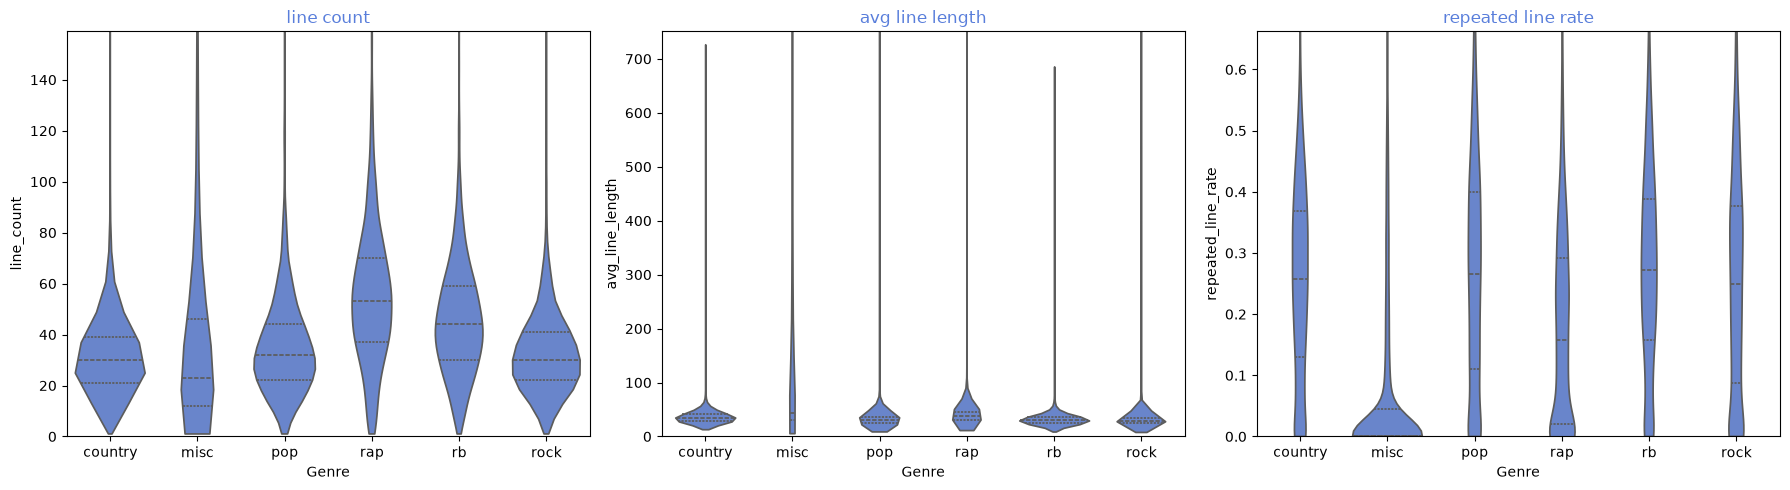

In [25]:
#Structure of the music

def structure_stats(lyrics):
    text = annotation_re.sub('', lyrics)
    lines = [l.strip() for l in text.split('\n') if l.strip()]
    if not lines:
        return pd.Series({'line_count': 0, 'avg_line_length': np.nan, 'repeated_line_rate': np.nan})
    return pd.Series({
        'line_count': len(lines),
        'avg_line_length': np.mean([len(l) for l in lines]),
        'repeated_line_rate': 1 - len(set(lines)) / len(lines),
    })

structure_metrics = ['line_count', 'avg_line_length', 'repeated_line_rate']
sample_df[structure_metrics] = sample_df['lyrics'].apply(structure_stats)
display(sample_df.groupby('tag')[structure_metrics].mean().round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, structure_metrics):
    sns.violinplot(data=sample_df, x='tag', y=metric, color=pink, inner='quartile', cut=0, ax=ax)
    ax.set_ylim(0, sample_df[metric].quantile(0.99))  # clip long tail
    ax.set_title(metric.replace('_', ' '), color=SECONDARY_COLOR, fontweight='normal')
    ax.set_xlabel('Genre')
plt.tight_layout()
plt.show()

This analysis removes bracketed Genius annotations before measuring lyric structure. For each song, it calculates the number of non-empty lines and related structure statistics. Repetition and line structure may provide useful exploratory context for sentiment analysis, while the genre-classification task can use only patterns present in the lyrics. These measurements are candidates for investigation, not sentiment labels.

<h3 style="color: #597edb; font-weight: 400;">3.3 Multivariate Analysis <a id="P13"></a></h3>

<h4>3.3.1 Views, genres, and artists <a id="P131"></a></h4>

<h5>Views by genre</h5>

,median_views,average_views
tag,,
country,153.0,2067.404501
pop,107.0,2252.091403
rock,98.0,2726.447655
rb,91.0,6256.137030
rap,71.0,5479.774466
misc,20.0,1539.413652


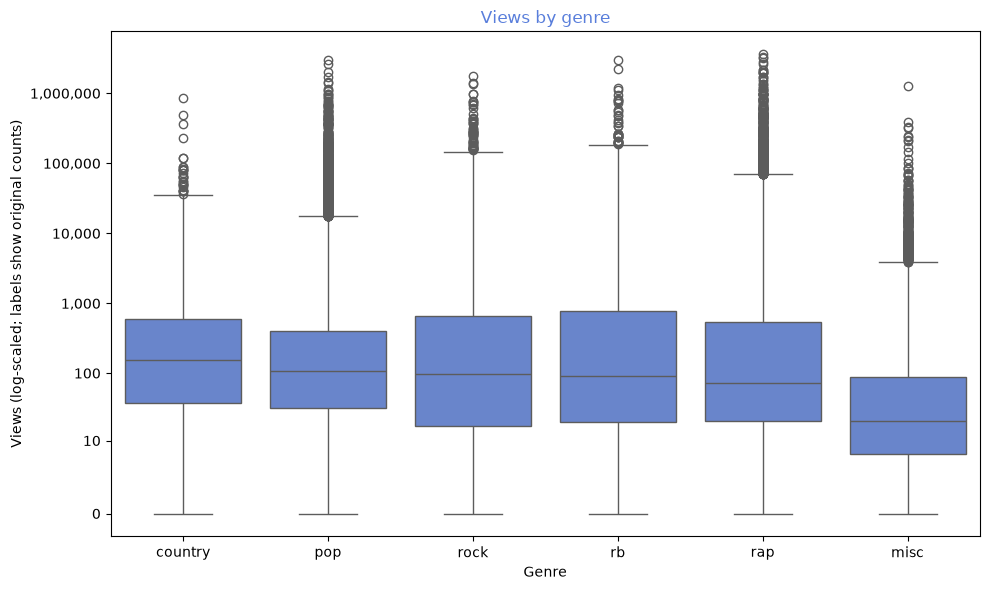

In [26]:
# Plot log-transformed views, with y-axis tick labels shown as original view counts
plot_df = df_train[['tag', 'views']].copy()
plot_df['log_views'] = np.log1p(plot_df['views'])
view_ticks = [0] + [10**i for i in range(1, 8)]
view_ticks = [v for v in view_ticks if v <= plot_df['views'].max()]

views_by_genre = (
    plot_df.groupby('tag')['views']
    .agg(median_views='median', average_views='mean')
    .sort_values('median_views', ascending=False)
)
display(views_by_genre)
genre_order = views_by_genre.index

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data=plot_df,
    x='tag',
    y='log_views',
    order=genre_order,
    color=pink,
    showfliers=True,
    ax=ax
)

ax.set_yticks(np.log1p(view_ticks))
ax.set_yticklabels([f'{v:,}' for v in view_ticks])
ax.set_title('Views by genre', color=SECONDARY_COLOR, fontweight='normal')
ax.set_xlabel('Genre')
ax.set_ylabel('Views (log-scaled; labels show original counts)')
plt.tight_layout()
plt.show()

The boxplot shows high-view outliers across genres. These extreme values inflate the mean, so interpret average views cautiously; the median is a more robust measure of a typical song. Treat extreme values as candidates for investigation rather than removing them automatically.

<h5>Views by artist</h5>

In [27]:
top_10_artists = (
    df_train.groupby('artist', as_index=False)['views']
    .sum()
    .nlargest(10, 'views')
    .reset_index(drop=True)
)

display(top_10_artists)

,artist,views
0,Drake,14539018
1,Eminem,6705635
2,2Pac,5893474
3,Genius English Translations,5410296
4,Taylor Swift,5112263
5,XXXTENTACION,4496096
6,The Weeknd,4072403
7,Childish Gambino,3916886
8,A$AP Ferg,3721960
9,A Boogie wit da Hoodie,3168133


<h5>Genre distribution by decade</h5>

tag,country,misc,pop,rap,rb,rock
decade,,,,,,
1900,0,61,3,0,0,0
1910,0,66,8,0,0,0
1920,24,49,21,0,9,0
1930,18,19,19,0,2,1
1940,12,15,37,0,3,0
1950,76,26,264,0,32,32
1960,264,29,960,0,146,289
1970,293,48,1330,8,276,679
1980,168,37,2218,138,177,1015


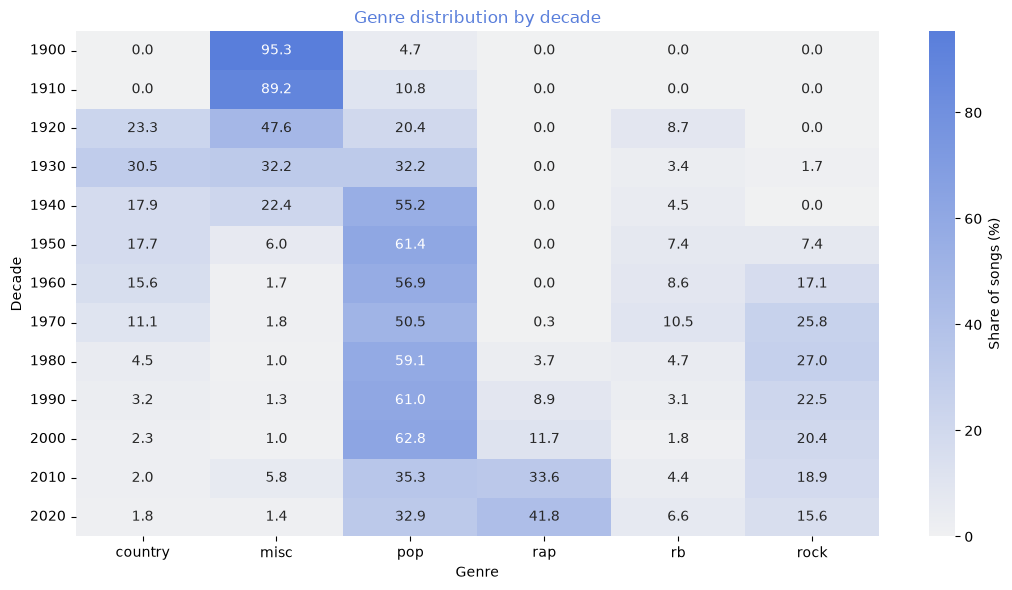

In [28]:
year_genre_df = df_train.loc[clean_year.index, ['tag']].copy()
year_genre_df['year'] = clean_year
year_genre_df['decade'] = (year_genre_df['year'] // 10) * 10

decade_genre_counts = pd.crosstab(year_genre_df['decade'], year_genre_df['tag'])
decade_genre_pct = decade_genre_counts.div(decade_genre_counts.sum(axis=1), axis=0) * 100

display(decade_genre_counts)

plt.figure(figsize=(11, 6))
sns.heatmap(
    decade_genre_pct,
    annot=True,
    fmt='.1f',
    cmap=sns.light_palette(SECONDARY_COLOR, as_cmap=True),
    cbar_kws={'label': 'Share of songs (%)'}
)
plt.title('Genre distribution by decade', color=SECONDARY_COLOR, fontweight='normal')
plt.xlabel('Genre')
plt.ylabel('Decade')
plt.tight_layout()
plt.show()

The decade-level genre mix shows how genre shares vary across release periods. These are within-decade proportions, not raw release counts; raw counts also reflect how much data the dataset contains for each decade.

<h5>Top artists by genre</h5>

In [29]:
# Top 3 artists per genre by number of songs
top_artists_per_genre = (
    df_train.groupby(['tag', 'artist'])
    .size()
    .rename('song_count')
    .reset_index()
    .sort_values(['tag', 'song_count', 'artist'], ascending=[True, False, True])
    .groupby('tag')
    .head(3)
    .reset_index(drop=True)
)

display(top_artists_per_genre)

,tag,artist,song_count
0,country,Willie Nelson,42
1,country,Dolly Parton,31
2,country,George Jones,30
3,misc,Emily Dickinson,74
4,misc,Abraham Lincoln,59
5,misc,Holy Bible (KJV),50
6,pop,Genius English Translations,309
7,pop,KIDZ BOP Kids,49
8,pop,Frank Sinatra,44
9,rap,Genius English Translations,163


The table lists the three artists with the most songs in each genre. These rankings are provisional: some records are credited to Genius translation accounts rather than the performing artist, so correct supported artist inconsistencies before interpreting the rankings.

<h2 style="color: #4166c4; font-weight: 400;">4. Preprocessing Plan <a id="P14"></a></h2>

The analysis suggests the following steps before modeling:

1. **Correct metadata carefully.** Parse `year` consistently and investigate implausible values. Use reliable release-date information to correct years where possible; leave unresolved values missing rather than guessing. Review likely Genius translation or romanization credits and correct artist names only when supported by the title structure or a reliable source.
2. **Normalize lyrics conservatively.** Apply the project?s Unicode-safe lyric normalization to standardize line endings, spacing, and punctuation without stripping accents or non-Latin scripts. Keep the original lyric text available. Treat removal of bracketed annotations, stopwords, or other modeling transformations as separate choices to evaluate.
3. **Audit and handle duplicates with an explicit policy.** Remove redundant complete rows from the training data where appropriate. Review repeated lyrics within each dataset and exact lyric overlap between train and test. These counts are based on raw text and may change after lyric normalization, so rerun the checks afterward. Repeated lyrics may represent versions or conflicting genre labels; resolve label conflicts rather than arbitrarily keeping one. Check lyric overlap when creating internal train/validation splits to prevent leakage.
4. **Preserve the official test set.** Audit duplicate records in both train and test, but do not drop or reorder official test rows when producing predictions: the submission must retain the expected rows and order. Keep corrections and any duplicate decisions reproducible, and save processed outputs separately from the source CSVs.

These steps address the data-quality issues found in the EDA while keeping uncertain corrections reviewable and protecting downstream model evaluation.